3115
351
359


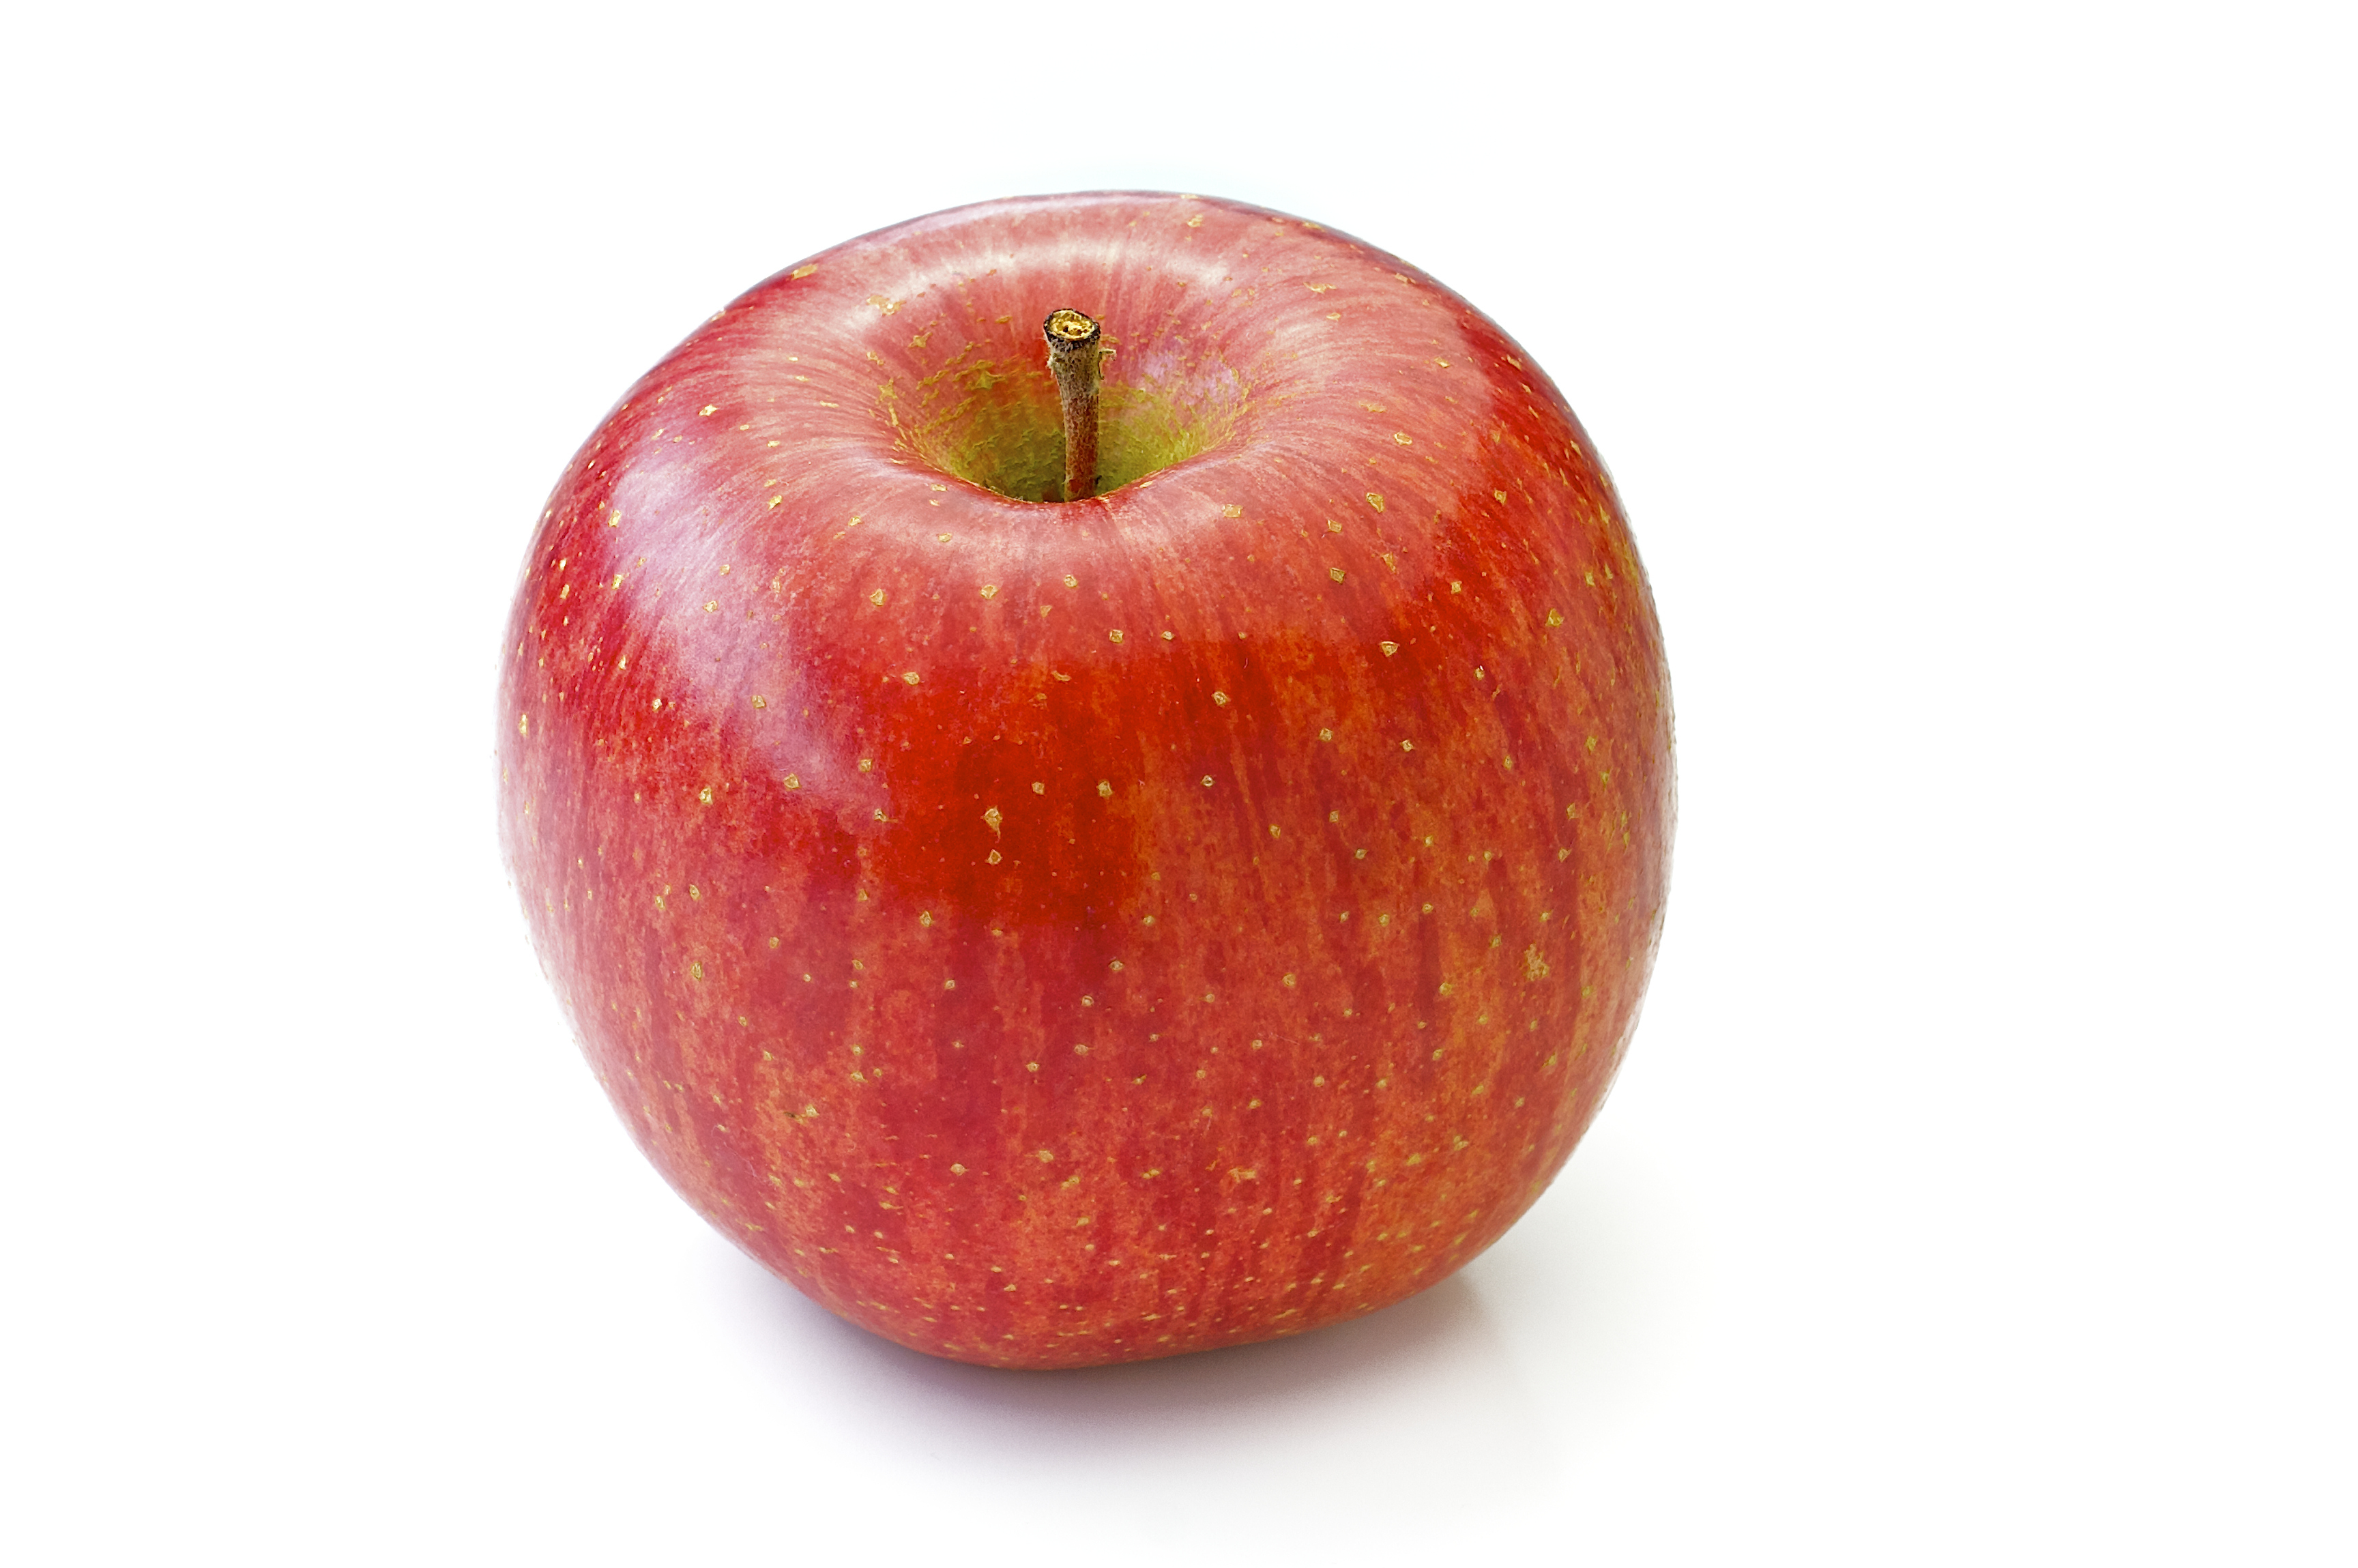

In [49]:
#dataset and code for produce classification - https://www.kaggle.com/code/databeru/fruit-and-vegetable-classification
#https://www.geeksforgeeks.org/python/pathlib-module-in-python/ - path also https://www.reddit.com/r/learnpython/comments/zf8qz7/help_understanding_relative_paths_in_python/
#https://www.tensorflow.org/tutorials/load_data/images - load from local
#https://developer.apple.com/metal/tensorflow-plugin/

#%pip install tensorflow-macos==2.12.0 - had some version issues are tried to downgrade to resolve.
#%pip install matplotlib seaborn scikit-learn coremltools

#https://stackoverflow.com/a/64448353 - cleanup of warnings
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # or any {'0', '1', '2'}
import tensorflow as tf


#https://coremltools.readme.io/v4.0/docs/introductory-quickstart

import tensorflow as tf
import numpy as np
import os
import PIL
import PIL.Image
import pathlib

#Getting data loaded and verifying it is reachable
data_dir = pathlib.Path("/Users/frederikdahlhansen/Documents/nowastemate-backend/ML/dataset")
#https://www.reddit.com/r/learnpython/s/QFiByrJ3Vp
train_dir = data_dir / "train"
val_dir = data_dir / "validation"
test_dir = data_dir / "test"

train_count = len(list(train_dir.glob('*/*')))
val_count = len(list(val_dir.glob('*/*')))
test_count = len(list(test_dir.glob('*/*')))

print(train_count)
print(val_count)
print(test_count)

apple_test = list(train_dir.glob('apple/*'))
PIL.Image.open(str(apple_test[5]))



Found 3115 files belonging to 36 classes.
Found 351 files belonging to 36 classes.
Found 359 files belonging to 36 classes.


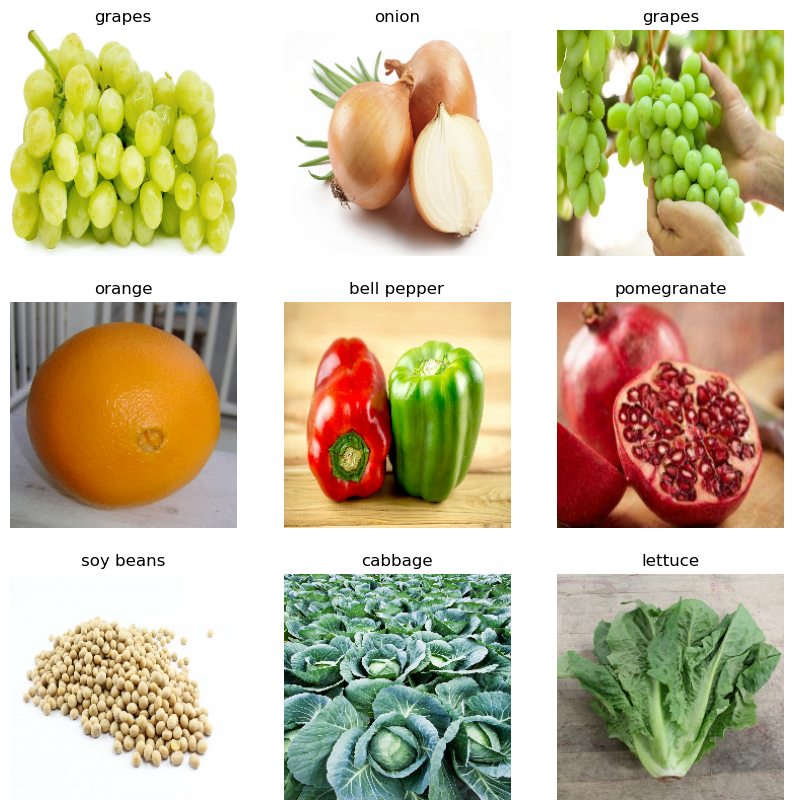

In [7]:
#https://www.tensorflow.org/api_docs/python/tf/keras/applications/MobileNetV2
#https://www.tensorflow.org/tutorials/images/transfer_learning
BATCH_SIZE = 32
#https://discuss.pytorch.org/t/size-of-input-images-tensor-to-mobilenet-and-other-pretrained-models/84359 
#Common size is 224. This is a more intensive process, but phone is powerful.
IMG_SIZE = (224, 224)

#https://blog.dailydoseofds.com/p/why-is-it-important-to-shuffle-your
train_dataset = tf.keras.utils.image_dataset_from_directory(train_dir,
                                                            shuffle=True,
                                                            batch_size=BATCH_SIZE,
                                                            image_size=IMG_SIZE)

validation_dataset = tf.keras.utils.image_dataset_from_directory(val_dir,
                                                                 shuffle=True,
                                                                 batch_size=BATCH_SIZE,
                                                                 image_size=IMG_SIZE)

test_dataset = tf.keras.utils.image_dataset_from_directory(test_dir,
                                                                 shuffle=False, #keep sorted to evaluate later
                                                                 batch_size=BATCH_SIZE,
                                                                 image_size=IMG_SIZE)



class_names = train_dataset.class_names

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 10))
for images, labels in train_dataset.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")



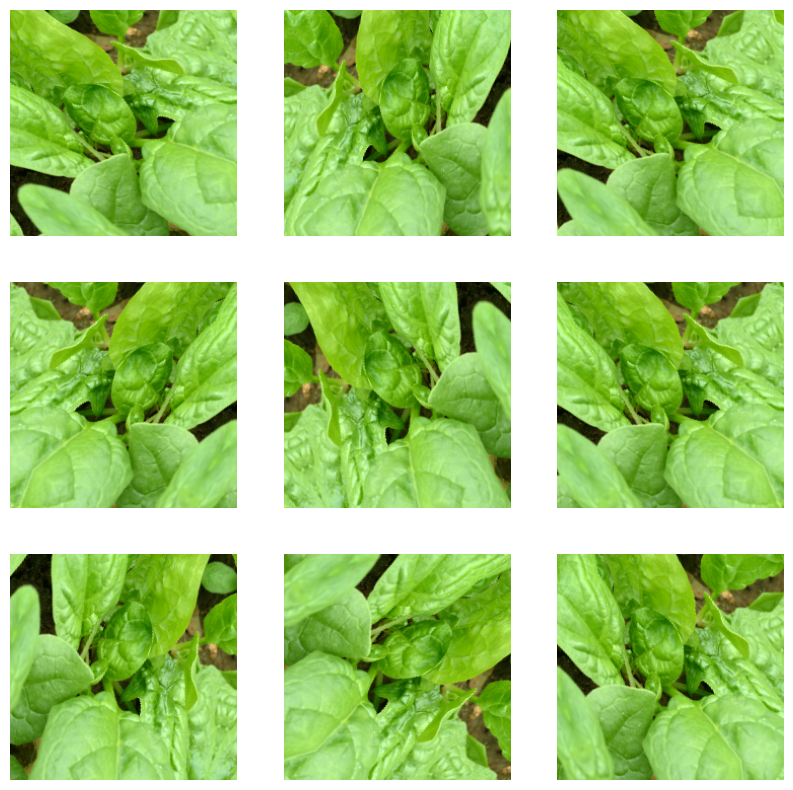

In [9]:
#adding variance to photos.
#This will help with real world pictures, where angle can differ

data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomFlip('horizontal'),
  tf.keras.layers.RandomRotation(0.2),
])

for image, _ in train_dataset.take(1):
  plt.figure(figsize=(10, 10))
  first_image = image[0]
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
    plt.imshow(augmented_image[0] / 255)
    plt.axis('off')



In [10]:
#model expect -1 to 1 values, but they come as 0 to 255 currently, this fixes this - https://www.tensorflow.org/tutorials/images/transfer_learning#rescale_pixel_values
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

#Create the base model from the pre-trained model MobileNet V2
IMG_SHAPE = IMG_SIZE + (3,)
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE,
                                               include_top=False,
                                               weights='imagenet')

image_batch, label_batch = next(iter(train_dataset))
feature_batch = base_model(image_batch)
print(feature_batch.shape)


#freeze the base model to ensure new data does not interfere
base_model.trainable = False



(32, 7, 7, 1280)


In [11]:
#https://www.tensorflow.org/tutorials/images/transfer_learning#add_a_classification_head

global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average = global_average_layer(feature_batch)
print(feature_batch_average.shape)

#https://keras.io/api/layers/core_layers/dense/
#https://www.geeksforgeeks.org/deep-learning/the-role-of-softmax-in-neural-networks-detailed-explanation-and-applications/
prediction_layer = tf.keras.layers.Dense(len(train_dataset.class_names), activation='softmax')
prediction_batch = prediction_layer(feature_batch_average)
print(prediction_batch.shape)

(32, 1280)
(32, 36)


In [12]:
#putting model together 
#https://www.tensorflow.org/tutorials/images/transfer_learning#add_a_classification_head
#https://keras.io/guides/making_new_layers_and_models_via_subclassing/ - info on layers and training
inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = global_average_layer(x)
#https://www.youtube.com/watch?v=_vydpu_VXtA
x = tf.keras.layers.Dropout(0.2)(x)
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)

In [13]:
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 tf.math.truediv (TFOpLambda  (None, 224, 224, 3)      0         
 )                                                               
                                                                 
 tf.math.subtract (TFOpLambd  (None, 224, 224, 3)      0         
 a)                                                              
                                                                 
 mobilenetv2_1.00_224 (Funct  (None, 7, 7, 1280)       2257984   
 ional)                                                          
                                                             

In [14]:
#https://www.geeksforgeeks.org/machine-learning/impact-of-learning-rate-on-a-model/
#https://www.geeksforgeeks.org/deep-learning/adam-optimizer/
base_learning_rate = 0.001
#https://www.tensorflow.org/api_docs/python/tf/keras/losses/SparseCategoricalCrossentropy
#https://www.tensorflow.org/api_docs/python/tf/keras/losses/CategoricalCrossentropy
#https://www.tensorflow.org/tutorials/images/data_augmentation#train_a_model
#https://www.geeksforgeeks.org/machine-learning/what-is-label-smoothing/ - to investigate later

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)



In [15]:
#initial_epochs = 10 - Tried with 10, but there looked to be more to performance to extract still
initial_epochs = 15

loss0, accuracy0 = model.evaluate(validation_dataset)

print("initial loss: {:.2f}".format(loss0))
print("initial accuracy: {:.2f}".format(accuracy0))

history = model.fit(train_dataset,
                    epochs=initial_epochs,
                    validation_data=validation_dataset)

11/11 [==============================] - 4s 84ms/step - loss: 3.8769 - accuracy: 0.0427
initial loss: 3.88
initial accuracy: 0.04
Epoch 1/15
98/98 [==============================] - 27s 242ms/step - loss: 1.9716 - accuracy: 0.4751 - val_loss: 0.7162 - val_accuracy: 0.8091
Epoch 2/15
98/98 [==============================] - 28s 250ms/step - loss: 0.8591 - accuracy: 0.7528 - val_loss: 0.4569 - val_accuracy: 0.8689
Epoch 3/15
98/98 [==============================] - 27s 252ms/step - loss: 0.6489 - accuracy: 0.8071 - val_loss: 0.3612 - val_accuracy: 0.8917
Epoch 4/15
98/98 [==============================] - 26s 237ms/step - loss: 0.5570 - accuracy: 0.8340 - val_loss: 0.3211 - val_accuracy: 0.9060
Epoch 5/15
98/98 [==============================] - 31s 297ms/step - loss: 0.4906 - accuracy: 0.8453 - val_loss: 0.2804 - val_accuracy: 0.9202
Epoch 6/15
98/98 [==============================] - 25s 231ms/step - loss: 0.4123 - accuracy: 0.8742 - val_loss: 0.2604 - val_accuracy: 0.9288
Epoch 7/15
9

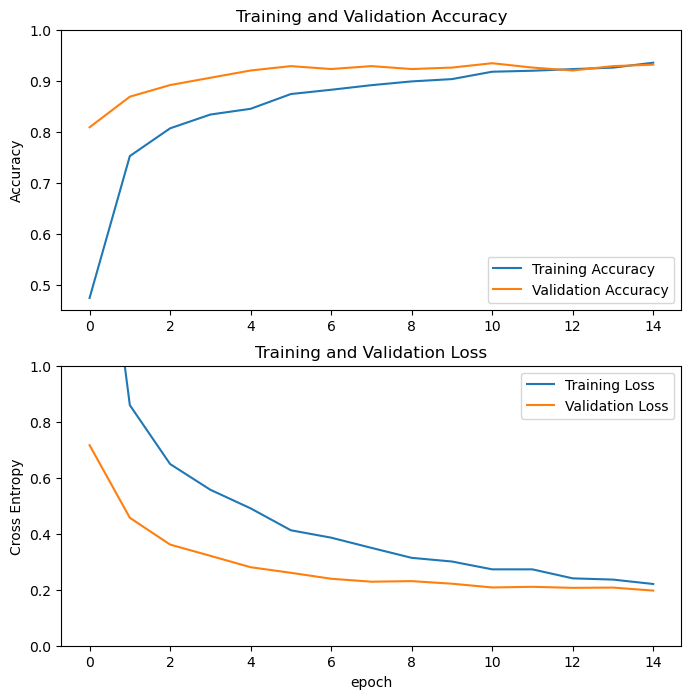

In [16]:
#https://www.tensorflow.org/tutorials/images/transfer_learning#learning_curves
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

In [18]:
#https://www.tensorflow.org/tutorials/images/transfer_learning#fine_tuning
base_model.trainable = True
print("Number of layers in the base model: ", len(base_model.layers))

#Fine-tune from this layer onwards
fine_tune_at = 100

#Freeze all the layers before the `fine_tune_at` layer
for layer in base_model.layers[:fine_tune_at]:
  layer.trainable = False

#recompile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate/10),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)
model.summary()

Number of layers in the base model:  154
Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 tf.math.truediv (TFOpLambda  (None, 224, 224, 3)      0         
 )                                                               
                                                                 
 tf.math.subtract (TFOpLambd  (None, 224, 224, 3)      0         
 a)                                                              
                                                                 
 mobilenetv2_1.00_224 (Funct  (None, 7, 7, 1280)       2257984   
 ional)                                                          
                    

In [19]:
#re-train
#https://www.tensorflow.org/tutorials/images/transfer_learning#fine_tuning
fine_tune_epochs = 10
total_epochs =  initial_epochs + fine_tune_epochs

history_fine = model.fit(train_dataset,
                         epochs=total_epochs,
                         initial_epoch=len(history.epoch),
                         validation_data=validation_dataset)

Epoch 16/25
98/98 [==============================] - 29s 248ms/step - loss: 0.4586 - accuracy: 0.8401 - val_loss: 0.2643 - val_accuracy: 0.9031
Epoch 17/25
98/98 [==============================] - 25s 234ms/step - loss: 0.3848 - accuracy: 0.8607 - val_loss: 0.2977 - val_accuracy: 0.9003
Epoch 18/25
98/98 [==============================] - 25s 234ms/step - loss: 0.3115 - accuracy: 0.8851 - val_loss: 0.2744 - val_accuracy: 0.8974
Epoch 19/25
98/98 [==============================] - 25s 233ms/step - loss: 0.2985 - accuracy: 0.8934 - val_loss: 0.2266 - val_accuracy: 0.9202
Epoch 20/25
98/98 [==============================] - 24s 229ms/step - loss: 0.2499 - accuracy: 0.9088 - val_loss: 0.2201 - val_accuracy: 0.9174
Epoch 21/25
98/98 [==============================] - 25s 232ms/step - loss: 0.2095 - accuracy: 0.9230 - val_loss: 0.2241 - val_accuracy: 0.9259
Epoch 22/25
98/98 [==============================] - 25s 230ms/step - loss: 0.2254 - accuracy: 0.9233 - val_loss: 0.1767 - val_accuracy:

12/12 [==============================] - 3s 251ms/step - loss: 0.2189 - accuracy: 0.9387
Test accuracy : 0.9387186765670776
12/12 [==============================] - 4s 192ms/step


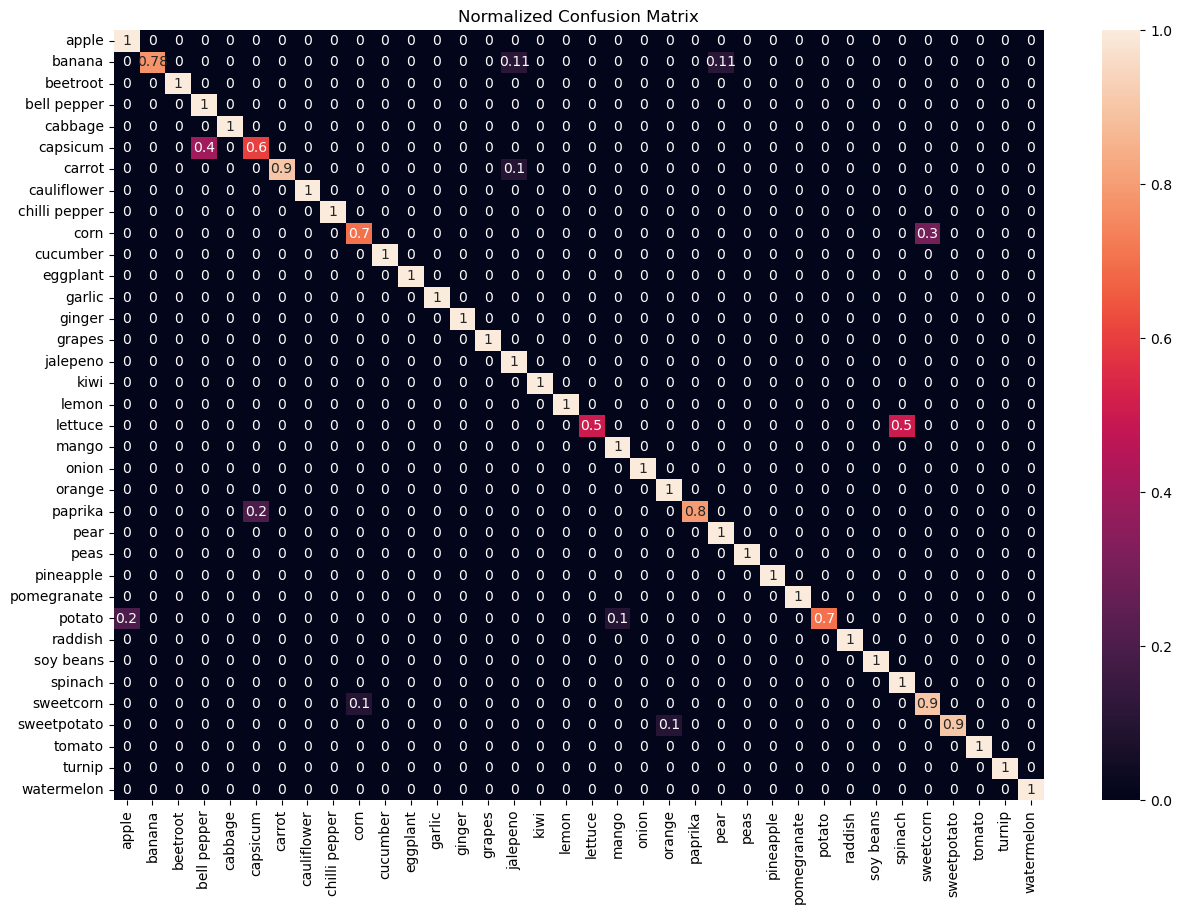

In [20]:
loss, accuracy = model.evaluate(test_dataset)
print('Test accuracy :', accuracy)
#https://www.kaggle.com/code/databeru/fruit-and-vegetable-classification/notebook
#predict on dataset and get the predictected class
pred = model.predict(test_dataset)
pred = np.argmax(pred,axis=1)


#https://stackoverflow.com/questions/56226621/how-to-extract-data-labels-back-from-tensorflow-dataset
y_test = np.concatenate([y for x, y in test_dataset], axis=0)

from sklearn.metrics import confusion_matrix
import seaborn as sns
#https://www.kaggle.com/code/databeru/fruit-and-vegetable-classification/notebook
cf_matrix = confusion_matrix(y_test, pred, normalize='true')
plt.figure(figsize = (15,10))
sns.heatmap(cf_matrix, 
            annot=True, 
            xticklabels = class_names, 
            yticklabels = class_names,
            )
plt.title('Normalized Confusion Matrix')
plt.show()

In [26]:
#https://stackoverflow.com/a/61212861
#https://coremltools.readme.io/v4.0/docs/introductory-quickstart
#https://coremltools.readme.io/v6.3/docs/tensorflow-2
#%pip install coremltools

import coremltools as ct


image_input = ct.ImageType(shape=(1, 224, 224, 3,))

#Set class labels
classifier_config = ct.ClassifierConfig(class_names)

#Convert the model using the Unified Conversion API
core_model = ct.convert(
    model, inputs=[image_input], classifier_config=classifier_config,
)

Converting TF Frontend ==> MIL Ops: 100%|███| 430/430 [00:00<00:00, 3632.43 ops/s]
Running MIL frontend_tensorflow2 pipeline: 100%|█| 7/7 [00:00<00:00, 111.92 passes
Running MIL default pipeline: 100%|██████████| 95/95 [00:01<00:00, 85.97 passes/s]
Running MIL backend_mlprogram pipeline: 100%|█| 12/12 [00:00<00:00, 307.07 passes/


In [37]:
#Set model author name
core_model.author = "NoWasteMate Group"

#Set a short description for the Xcode UI
core_model.short_description = "Helps classify produce that does not have barcodes available"

#Set a version for the model
core_model.version = "1.0"

In [39]:
#https://stackoverflow.com/questions/78229310/difference-between-mlmodel-and-mlpackage'
#https://coremltools.readme.io/v4.0/docs/introductory-quickstart

#Save model
core_model.save("ProduceClassifier.mlpackage")
